# NewsRetrieval — Etapa II

Demostración del corpus, clasificación y K-Means con los artefactos entregados. No descarga datos, no reentrena modelos ni escribe resultados.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from pipelines import get_preprocessing_configs, get_vectorizer_configs

ROOT = Path('.')  # Ejecutar desde la raíz del repositorio.
def read(name):
    return pd.read_csv(ROOT / name, sep='\t')
def show_text(frame):
    display(frame.style.set_properties(**{'white-space': 'pre-wrap', 'text-align': 'left',
                                          'max-width': '650px', 'vertical-align': 'top'}).hide(axis='index'))
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)
raw = read('data/news_raw_corpus.tsv')
data = read('labeled_documents.tsv')
experiments = read('experiments.tsv')
cls_meta = json.loads((ROOT / 'results/classifier_best_metadata.json').read_text())
km_meta = json.loads((ROOT / 'results/kmeans_best_metadata.json').read_text())
assert len(experiments) == experiments.experiment_id.nunique() == 101

## 1. Corpus de noticias

Reutilizamos las noticias en inglés de Etapa I y sus categorías originales. El texto une título y cuerpo; las particiones ya están fijadas antes del aprendizaje.

In [2]:
display(pd.Series({'noticias': len(data), 'categorías': data.category.nunique(),
                   'IDs únicos': data.document_id.nunique()}).to_frame('cantidad'))
display(data[['document_id', 'category', 'split', 'text']].head(5))
sample = raw.iloc[0]
show_text(pd.DataFrame({'campo': ['título', 'cuerpo (fragmento)', 'texto combinado (fragmento)'],
                        'contenido': [sample.title, sample['description/body'][:300],
                                      data.set_index('document_id').loc[sample.id, 'text'][:500]]}))
display(pd.crosstab(data.category, data.split)[['train', 'dev', 'test']])

,cantidad
noticias,2000
categorías,3
IDs únicos,2000


,document_id,category,split,text
0,N67eca7076987f66c5fe9,finanzas,train,China’s fertility crisis is evidence of its modernization success China’s only daughters were ra...
1,N0cdb1412b34517f13f00,deportes,train,"1964 Australian Paralympic medalist Trevor French dies Yesterday, 1964 Summer Paralympic swimmer..."
2,N19b9584195d4d2ee48c4,deportes,train,"Chicago Bears select Marquess Wilson in seventh round of NFL draft Yesterday, the Chicago Bears ..."
3,Nd1bc1b8f3d438c156073,deportes,train,Brawn GP take over Honda Formula One team Brawn GP have completed their takeover of the Honda Ra...
4,Nf7e2f57b1361e9256a1e,tecnologia,train,"Apple to hold media event on September 1, may update iPods and Apple TV Apple Inc. will hold a m..."


campo,contenido
título,In Memoriam: Barry Steinhardt
cuerpo (fragmento),"Barry Steinhardt, a lifelong privacy champion and an early leader in the battle for digital civil liberties who served as EFF’s president in 1998-99, died last week at age 73. A Connecticut native, Steinhardt led the Vermont and Pennsylvania affiliates of the American Civil Liberties Union before be"
texto combinado (fragmento),"In Memoriam: Barry Steinhardt Barry Steinhardt, a lifelong privacy champion and an early leader in the battle for digital civil liberties who served as EFF’s president in 1998-99, died last week at age 73. A Connecticut native, Steinhardt led the Vermont and Pennsylvania affiliates of the American Civil Liberties Union before becoming associate director of the national ACLU. There, he helped spearhead the fight to overturn much of the Communications Decency Act, resulting in the U.S. Supreme Cou"


split,train,dev,test
category,,,
deportes,467,100,100
finanzas,467,100,100
tecnologia,466,100,100


## 2. Normalización y representación

Las tres normalizaciones se aplican al mismo fragmento real. Después mostramos pesos binarios, frecuencias y TF-IDF en tres documentos train. Este ejemplo pequeño no modifica los vectorizadores guardados.

In [3]:
example = data.loc[data.split.eq('train'), 'text'].iloc[0][:650]
normalizers = get_preprocessing_configs()
show_text(pd.DataFrame([{'configuración': 'original', 'texto': example}] +
    [{'configuración': name, 'texto': normalizer.transform([example])[0]}
     for name, normalizer in normalizers.items()]))

configuración,texto
original,"China’s fertility crisis is evidence of its modernization success China’s only daughters were raised to pursue education, independence and opportunity. Now, those same qualities are increasingly seen as obstacles to marriage and motherhood."
norm_1_baseline,"china’s fertility crisis is evidence of its modernization success china’s only daughters were raised to pursue education, independence and opportunity. now, those same qualities are increasingly seen as obstacles to marriage and motherhood."
norm_2_stopwords,china fertility crisis evidence modernization success china daughters raised pursue education independence opportunity qualities increasingly seen obstacles marriage motherhood
norm_3_lemma,china fertility crisis evidence modernization success china daughter raise pursue education independence opportunity quality increasingly see obstacle marriage motherhood


In [4]:
small = data.loc[data.split.eq('train')].head(3)
texts = normalizers['norm_2_stopwords'].transform(small.text.tolist())
for name, vectorizer in get_vectorizer_configs().items():
    matrix = vectorizer.fit_transform(texts)
    names = vectorizer.get_feature_names_out()
    indices = np.argsort(np.asarray(matrix.sum(axis=0)).ravel())[::-1][:6]
    display(Markdown(f"**{name} · n-gramas {vectorizer.ngram_range}**"))
    display(pd.DataFrame(matrix[:, indices].toarray(), index=small.document_id,
                         columns=names[indices]).round(3))

**vec_binary_1 · n-gramas (1, 1)**

,yesterday,year,team,seen,opportunity,games
document_id,,,,,,
N67eca7076987f66c5fe9,0,0,0,1,1,0
N0cdb1412b34517f13f00,1,1,1,1,0,1
N19b9584195d4d2ee48c4,1,1,1,0,1,1


**vec_freq_1_2 · n-gramas (1, 2)**

,games,year,opportunity,team,yesterday,seen
document_id,,,,,,
N67eca7076987f66c5fe9,0,0,1,0,0,1
N0cdb1412b34517f13f00,3,2,0,1,1,1
N19b9584195d4d2ee48c4,2,1,2,2,1,0


**vec_tfidf_1 · n-gramas (1, 1)**

,games,opportunity,seen,team,year,yesterday
document_id,,,,,,
N67eca7076987f66c5fe9,0.000,0.707,0.707,0.000,0.000,0.000
N0cdb1412b34517f13f00,0.750,0.000,0.250,0.250,0.500,0.250
N19b9584195d4d2ee48c4,0.535,0.535,0.000,0.535,0.267,0.267


**vec_tfidf_1_2 · n-gramas (1, 2)**

,games,opportunity,seen,team,year,yesterday
document_id,,,,,,
N67eca7076987f66c5fe9,0.000,0.707,0.707,0.000,0.000,0.000
N0cdb1412b34517f13f00,0.750,0.000,0.250,0.250,0.500,0.250
N19b9584195d4d2ee48c4,0.535,0.535,0.000,0.535,0.267,0.267


## 3. Clasificación supervisada

MultinomialNB, LogisticRegression y LinearSVC predicen la categoría. Macro-F1 en dev selecciona la configuración; solo el ganador se reajusta con train+dev para test.

In [5]:
cls_metrics = read('classification_metrics.tsv')
cls_pred = read('classification_predictions.tsv')
display(cls_metrics.query("split == 'dev'").sort_values('macro_f1', ascending=False))
cls_id = cls_meta['experiment_id']
display(experiments.loc[experiments.experiment_id.eq(cls_id),
    ['experiment_id', 'method', 'normalization', 'representation', 'hyperparameters']])
display(cls_metrics.query("split == 'test'"))
per_class = read('classification_per_class_metrics.tsv')
display(per_class[per_class.experiment_id.isin([cls_id, 'test'])])
confusion = read('classification_confusion_matrices.tsv')
for exp_id in [cls_id, 'test']:
    group = confusion[confusion.experiment_id.eq(exp_id)]
    display(Markdown(f"**Matriz: {exp_id} · {group['split'].iloc[0]} (filas reales, columnas predichas)**"))
    display(group.pivot(index='true_label', columns='predicted_label', values='count'))

,experiment_id,model,split,accuracy,macro_precision,macro_recall,macro_f1
1,EXP_A_046,LogisticRegression,dev,0.896667,0.896824,0.896667,0.896555
2,EXP_A_041,LinearSVC,dev,0.893333,0.892844,0.893333,0.893028
0,EXP_A_037,MultinomialNB,dev,0.886667,0.886029,0.886667,0.886172


,experiment_id,method,normalization,representation,hyperparameters
45,EXP_A_046,LogisticRegression,norm_2_stopwords,vec_tfidf_1_2,"C=5.0, max_iter=2000"


,experiment_id,model,split,accuracy,macro_precision,macro_recall,macro_f1
3,test,LogisticRegression,test,0.893333,0.89601,0.893333,0.893738


,experiment_id,model,split,class_label,precision,recall,f1_score,support
3,EXP_A_046,LogisticRegression,dev,deportes,0.960396,0.97,0.965174,100.0
4,EXP_A_046,LogisticRegression,dev,finanzas,0.844660,0.87,0.857143,100.0
5,EXP_A_046,LogisticRegression,dev,tecnologia,0.885417,0.85,0.867347,100.0
9,test,LogisticRegression,test,deportes,0.989796,0.97,0.979798,100.0
10,test,LogisticRegression,test,finanzas,0.881720,0.82,0.849741,100.0
11,test,LogisticRegression,test,tecnologia,0.816514,0.89,0.851675,100.0


**Matriz: EXP_A_046 · dev (filas reales, columnas predichas)**

predicted_label,deportes,finanzas,tecnologia
true_label,,,
deportes,97,3,0
finanzas,2,87,11
tecnologia,2,13,85


**Matriz: test · test (filas reales, columnas predichas)**

predicted_label,deportes,finanzas,tecnologia
true_label,,,
deportes,97,1,2
finanzas,0,82,18
tecnologia,1,10,89


In [6]:
winner_dev = cls_pred[cls_pred.experiment_id.eq(cls_id)].copy()
winner_dev['acierto'] = winner_dev.gold_label.eq(winner_dev.predicted_label)
five = pd.concat([winner_dev[winner_dev.acierto].head(3), winner_dev[~winner_dev.acierto].head(2)])
five = five.merge(raw[['id', 'title']], left_on='document_id', right_on='id')
display(five[['document_id', 'title', 'gold_label', 'predicted_label', 'split', 'acierto']])
classifier = joblib.load(ROOT / 'results/classifier_best.joblib')
# Inferencia puntual del ajuste final: no se confunde con las predicciones dev anteriores.
one_test = data[data.split.eq('test')].head(1)
display(pd.DataFrame({'document_id': one_test.document_id, 'real': one_test.category,
                     'predicción final': classifier.predict(one_test.text.tolist())}))

,document_id,title,gold_label,predicted_label,split,acierto
0,N380946c6626f833ab8a5,Kosmos-3M rocket launches six Orbcomm satellites,tecnologia,tecnologia,dev,True
1,Ncf92e222862262b47d01,Dark matter lacks extra gravitational force,tecnologia,tecnologia,dev,True
2,N5f4c1cba1f1f4dcb43ba,Euro reaches ten month low against US dollar,finanzas,finanzas,dev,True
3,Nd09e2955f37f6395d63f,Collyer brothers to bid for Everton F.C.?,finanzas,deportes,dev,False
4,N50892761a6ec517447da,Jeff Jones resigns as president of Uber,tecnologia,finanzas,dev,False


,document_id,real,predicción final
1700,N856e095ed922fb6abb6b,deportes,deportes


Estos son los diez casos de dev ya analizados. Se conservan las explicaciones concretas sobre el contenido de cada noticia.

In [7]:
errors = read('classification_error_analysis.tsv')
reviewed = errors[errors.review_note.fillna('').str.strip().ne('')].head(10).copy()
reviewed['review_note'] = reviewed['review_note'].str.replace(';', ',', regex=False)
reviewed['review_note'] = reviewed['review_note'].str.replace('Revisión analítica (no humana institucional): ', '', regex=False)
assert len(reviewed) == 10
for row in reviewed.itertuples():
    display(Markdown(f"**{row.document_id} · {row.gold_label} → {row.predicted_label}**"))
    show_text(pd.DataFrame({'fragmento': [row.text], 'explicación': [row.review_note]}))

**Nd09e2955f37f6395d63f · finanzas → deportes**

fragmento,explicación
"Collyer brothers to bid for Everton F.C.? Rumours in London and Merseyside have linked Paul and Oliver Collyer, creators of the football management series Championship Manager, with a possible bid for Premiership football team Everton. The Goodison Park club, under the chairmanship of former Coronation Street actor Bill Kenwright, were subjects of a failed takeover bid in August 2004. After suffering the blow of failing to get beyond the qualifying stage of the Champions League, Kenwright is known to have recently sought additional investments in the club. While a move is not thought to be imminent, the recent takeover of the brothers' games development company Sports Interactive by game giant SEGA could well prove the catalyst for action by the lifelong Evertonians. The company's PR guru Miles Jacobson was forced into an official denial of the story soon after the takeover news broke on Tuesday morning. The Collyers themselves have as yet been unavailable for comment.","Revisión analítica (no humana institucional): La posible compra del Everton y la búsqueda de inversiones sustentan finanzas; los nombres del club, Champions League y aficionados aportan vocabulario deportivo dominante. Mezcla temática empresarial/deportiva, sin evidencia para cambiar la etiqueta."


**N50892761a6ec517447da · tecnologia → finanzas**

fragmento,explicación
"Jeff Jones resigns as president of Uber Jeff Jones, president of ride-sharing company Uber Technologies, announced his resignation on Sunday. Jones was hired last October to helm the company that is known for their ride-sharing application, Uber, which has a reported 40 million monthly users. Recently in Jones's presidency of Uber, the ride-sharing company was involved in numerous controversies surrounding an alleged culture of at the company, stemming from allegations blogged by Susan Fowler, a former Uber engineer, claiming sexual harassment against her and other women working for Uber. In a statement to tech blog Recode, Jones claimed the situation he was working with at Uber was one inconsistent with ""the beliefs and approach to leadership that have guided my career"" and he could not remain the company's president. Jones, who was previously the Chief Marketing Officer at Target before joining Uber, came to the decision to resign after it was announced Uber would be hiring a Chief O","Revisión analítica (no humana institucional): La dimisión de Jeff Jones trata liderazgo y controversias laborales de Uber, aunque la empresa y su aplicación justifican la categoría tecnológica. El contenido corporativo aproxima el documento a finanzas; no describe una innovación técnica."


**N889c42c4a66fe55e4f97 · tecnologia → finanzas**

fragmento,explicación
"Australian Federal Police say Wikileaks committed no crime The Australian Federal Police (AFP) has stated that the whistle-blowing website known as WikiLeaks has committed no crimes in Australia by publishing over 250,000 United States diplomatic cables. An investigation by the AFP into the release of the cables revealed that Wikileaks had not broken any laws under Australian jurisdiction. "" not identified any criminal offences where Australia has jurisdiction and as a result have not commenced an investigation,"" said Robert McClelland, attorney-general of Australia in a statement to the press. ""As has previously been stated, given the documents published to date are classified by the United States, the primary jurisdiction for any investigation into the matter remains the United States."" The investigation into Wikileaks actions came after the Australian Government referred the release of U.S. diplomatic cables to the AFP. McClelland stated that the Government's reaction to the WikiLea","Revisión analítica (no humana institucional): El foco es la jurisdicción australiana sobre cables diplomáticos publicados por WikiLeaks. La plataforma conecta con tecnología, pero la investigación policial y las relaciones gubernamentales dominan el texto. Ambigüedad de cobertura de las tres categorías, no prueba de etiqueta incorrecta."


... (10 outputs left out)

**Nddbce17c23d823824e1d · tecnologia → finanzas**

fragmento,explicación
"Cloned cattle's milk and meat seem safe, according to new study A National Academy of Sciences report (.pdf) last year said that while the milk and meat from cloned animals would not likely make anyone sick, more research should be performed. Now, a new US-Japan study published in the April 11 online issue of the Proceedings of the National Academy of Sciences says that milk and meat from cloned cattle does indeed appear to meet industry standards and appears to be safe for human consumption. As BBC News reports, the scientists, led by Professor Jerry Yang from the University of Connecticut, compared the produce from two beef and four dairy clones, all derived from a single Holstein dairy cow and a single Japanese black bull, with the produce from normal animals of similar age and breed. The meat was analysed against more than 100 physiological, tissue and cellular components, while the milk was analysed for protein, fat and other variables. No significant differences between the produ","Revisión analítica (no humana institucional): La noticia sobre carne y leche de ganado clonado describe un estudio biotecnológico, compatible con tecnologia. Su vocabulario de producción, industria y consumo puede solaparse con noticias económicas; la confusión precisa no puede atribuirse causalmente sin estudiar pesos del modelo."


**N6f87a799a62e2aa67140 · finanzas → tecnologia**

fragmento,explicación
"Norway’s Telenor telecom faces lawsuit for giving user data to Myanmar junta ""We hope this will finally lead to accountability for the harms Telenor has caused Myanmar people through its conduct and its dangerous divestment.""",Revisión analítica (no humana institucional): El título combina una demanda contra Telenor con entrega de datos de usuarios a la junta de Myanmar. La etiqueta financiera convive con privacidad y telecomunicaciones; el cuerpo es muy breve y aporta poco contexto económico. Contexto insuficiente y mezcla temática.


## 5. Clustering con K-Means

Texto → normalización → vectorización → SVD opcional → L2 opcional → K-Means. Las categorías no intervienen en el ajuste ni en la selección. Se muestran alternativas representativas, no una búsqueda nueva.

In [8]:
dev_runs = read('clustering_dev_experiments.tsv')
representative_ids = ['EXP_B_002', 'EXP_B_012', 'EXP_B_018', 'EXP_B_019',
                      'EXP_B_021', 'EXP_B_022', 'EXP_B_024', 'EXP_B_027']
columns = ['experiment_id', 'normalization', 'representation', 'svd_components',
           'post_l2', 'n_clusters', 'silhouette_euclidean', 'cluster_sizes', 'selection_score']
display(dev_runs[dev_runs.experiment_id.isin(representative_ids)][columns])
km_id = km_meta['experiment_id']
display(experiments[experiments.experiment_id.eq(km_id)])
# Verificar la regla guardada usando solo silhouette y tamaños de dev.
counts = dev_runs.cluster_sizes.map(json.loads)
entropy = counts.map(lambda sizes: -sum(p*np.log(p) for p in np.array(sizes)/sum(sizes) if p > 0)/np.log(len(sizes)))
np.testing.assert_allclose(dev_runs.selection_score, dev_runs.silhouette_euclidean * entropy)
assert km_id == 'EXP_B_021'
print('El producto silhouette × entropía es histórico y no determina el ganador.')

display(Markdown('**Evidencia de dev: ajuste con train, términos originales y dos ejemplos por cluster**'))
show_text(read('clustering_dev_interpretation.tsv')[['cluster_id', 'top_10_words', 'document_id', 'excerpt']])

,experiment_id,normalization,representation,svd_components,post_l2,n_clusters,silhouette_euclidean,cluster_sizes,selection_score
1,EXP_B_002,norm_1_baseline,vec_freq_1_2,0,False,4,0.280941,"[79, 1, 215, 5]",0.137275
11,EXP_B_012,norm_3_lemma,vec_tfidf_1_2,0,False,4,0.008482,"[15, 6, 51, 228]",0.004514
17,EXP_B_018,norm_3_lemma,vec_tfidf_1_2,50,False,3,0.191004,"[55, 239, 6]",0.099161
18,EXP_B_019,norm_3_lemma,vec_tfidf_1_2,50,False,4,0.207356,"[9, 233, 52, 6]",0.102236
20,EXP_B_021,norm_3_lemma,vec_tfidf_1_2,50,True,3,0.076484,"[95, 103, 102]",0.076439
21,EXP_B_022,norm_3_lemma,vec_tfidf_1_2,50,True,4,0.092389,"[103, 95, 72, 30]",0.086900
23,EXP_B_024,norm_3_lemma,vec_tfidf_1_2,100,False,3,0.147443,"[56, 238, 6]",0.077198
26,EXP_B_027,norm_3_lemma,vec_tfidf_1_2,100,True,3,0.051268,"[103, 108, 89]",0.051114


,experiment_id,task,normalization,representation,method,hyperparameters,dev_metric,selected,selection_metric,selected_overall,notes,svd_components,post_l2,ngram_range,selection_score
92,EXP_B_021,clustering,norm_3_lemma,vec_tfidf_1_2,KMeans,n_clusters=3; n_init=10; init=k-means++; max_iter=300; random_state=0; svd=50; post_l2=True,0.076484,True,dev_finalist_review_separation_stability_sizes_interpretability,True,001-012 normalization/representation; 013-017 one KMeans factor vs 012; 018-029 SVD dimensions/L...,50.0,True,"(1, 2)",0.076439


El producto silhouette × entropía es histórico y no determina el ganador.


**Evidencia de dev: ajuste con train, términos originales y dos ejemplos por cluster**

cluster_id,top_10_words,document_id,excerpt
0,team | win | final | score | minute | match | game | goal | race | cup,N236a24dcb2c3d285873d,"6-1, 6-2, 3-6 and 6-3: Djokovic beats Federer and advances to Aus Open 2016 Final Today, defending champion Novak Djokovic defeated Swiss professional Roger Federer 6–1, 6–2, 3–6 6–3 in the Australian Open 2016 semi-final. Djokovic has previously featured in five Australian finals, winning them all. Serbian Djokovic won the first set 6–1 in just 22 minutes, with ten aces total through the match. It took 32 minutes to complete the second set 6–3, with Federer winning three games of the set, and s"
0,team | win | final | score | minute | match | game | goal | race | cup,N955da7a50f6dcf2a86b3,"Bollywood cricket victory in Yorkshire charity match A cricket team made up of Bollywood celebrities has beaten a Yorkshire opposition in a charity cricket match at Headingley, held as part of the International Indian Film Academy (""IIFA"") Weekend in Yorkshire, England, celebrating Indian cinema and its stars. The ""Bolly 11"" team, consisting of Indian actors and cricketers, took on the Yorkshire 11 which featured former English cricketers, British TV stars and musicians and two members of Parlia"
1,say | company | government | oil | state | trade | year | country | energy | report,Nfb5191ac2bf96ede3c20,"Afghan opium plantings expected to be up 40% from 2005 In spite of the U.S. Government's ""five pillar counternarcotics strategy"" for combating narcotics in Afghanistan, approximately 140,000 hectares of poppies were planted in Afghanistan this year, according to the Associated Press. This would be an increase of about 40 percent from 2005. The United Nations Office on Drugs and Crime's Rapid Assessment Survey released last month indicates that poppy planting for 2006 increased in 13 provinces, d"
1,say | company | government | oil | state | trade | year | country | energy | report,N77e74354cb4ae332c665,"'Davos man' versus 'Camp Igloo'; 42nd World Economic Forum convenes in Swiss alps Germany's Chancellor Angela Merkel gave yesterday's opening address to the 42nd meeting of the World Economic Forum (WEF), which is facing a distinctly different geo-political landscape from twelve months ago. Outside the WEF security cordon, in the sub-zero temperatures of Davos' train station car park, the local incarnation of the Occupy movement are setting up 'Camp Igloo'; but, with little hope of the archetype"
2,launch | space | planet | google | apple | user | new | microsoft | datum | china,Nb5d6a2d58cc9a9c9a82d,"Computer professionals celebrate 10th birthday of A.L.I.C.E. More than 50 programmers, scientists, students, hobbyists and fans of the A.L.I.C.E. chat robot gathered in Guildford, U.K. on Friday to celebrate the tenth birthday of the award winning A.I. On hand was the founder the Loebner Prize, an annual Turing Test, designed to pick out the world's most human computer according to an experiment laid out by the famous British mathematician Alan Turing more then 50 years ago. Along with A.L.I.C.E"
2,launch | space | planet | google | apple | user | new | microsoft | datum | china,Nbdd32945d036a863972b,"Complaint made against internet provider iHug upheld A complaint made against Internet service provider (ISP) iHug by M. McNatty has been upheld by the Advertising Standards Authority (ASA). McNatty complained that he was not told of the special conditions of banner adverts he saw on the iHug website. McNatty said: ""I signed up but discovered I had shot over my limit and iHUG had reduced my download speed from 100 to 64kps. I rang iHUG and they explained that I had gone over my 1 GB traffic allo"


La selección compara los finalistas en dev: separación positiva, estabilidad entre semillas, tamaños e interpretación manual de términos y documentos. Se eligió EXP_B_021 por grupos útiles y estables; la silhouette entre conteos y SVD+L2 no es directamente comparable. La revisión es cualitativa y no usa categorías ni test.

## 6. Interpretación de los clusters

Los términos son promedios de pesos en el vocabulario original. Los ejemplos se eligen por distancia al centroide en el espacio del modelo final, sin categorías.

,cluster_id,size_train_dev,size_test,top_10_words
0,0,504,92,ov | team | score | win | game | goal | match | australia | cup | minute
1,1,641,113,google | space | launch | apple | user | internet | say | microsoft | new | computer
2,2,555,95,say | company | year | government | state | bank | new | airline | united | oil


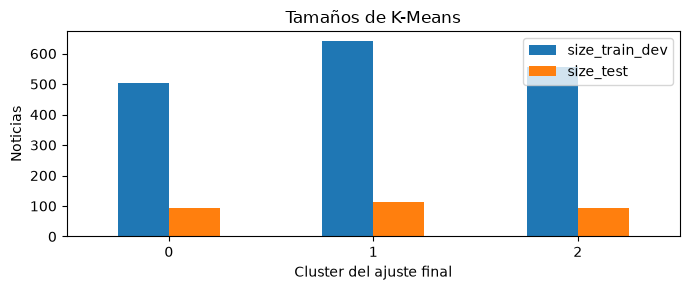

**Cluster 0 · dos documentos representativos**

document_id,fragmento
N2920f3fd3548c584b6d0,"Canberra United lose first game since January 2011 Before a crowd of 575 on Saturday at Wembley Park in Box Hill, metropolitan Melbourne, Australia, W-League team Canberra United lost to the Melbourne Victory 0–3 in the team's first loss since January of last year. Two of the Victory's goals came in the first half, with Canadian import Jessica McDonald and English import Jessica Fishlock each scoring for the Victory. Enza Barilla scored the third unanswered goal for the Victory in the second hal"
N31f7d167ed64662708cf,"American tennis player Andre Agassi retires Andre Agassi retired after a defeat by Benjamin Becker of Germany at the U.S. Open. The score was 7-6, 6-7, 6-4, 7-5. After the match ended, Thirty six year old Agassi sobbed as the 24,000 fans gave him a standing ovation lasting four minutes. ""The scoreboard said I lost today, but what the scoreboard doesn't say is what it is I've found,"" Agassi told the crowd, tears streaming down his cheeks, his voice cracking with emotion. ""Over the last 21 years,"


**Cluster 1 · dos documentos representativos**

document_id,fragmento
N0c3785f764fa0ef3d7fc,"Israel Journal: Is Yossi Vardi a good father to his entrepreneurial children? Wikinews reporter David Shankbone is currently, courtesy of the Israeli government and friends, visiting Israel. This is a first-hand account of his experiences and may — as a result — not fully comply with Wikinews' neutrality policy. Please note this is a journalism experiment for Wikinews and put constructive criticism on the collaboration page. Dr. Yossi Vardi is known as Israel's 'Father of the Entrepreneur', and"
Na6813ef63597b0be0959,"Earth Day 2009 celebrated around the globe Today is the 39th observance of Earth Day in the northern hemisphere. Earth day is celebrated in Autumn on November 30 in the southern hemisphere. Senator Gaylord Nelson initiated the first Earth Day in April 1970 in the United States, and it is now celebrated by over 1 billion people in over 170 countries worldwide. Earth Day is the biggest environmental event which addresses issues and educates people on environmental awareness on a global scale. This"


**Cluster 2 · dos documentos representativos**

document_id,fragmento
Nf3989ceb32a87507e038,"Denny's Super Bowl free 'Grand Slam Breakfast' brings 2 million diners Denny's 1,600 chain restaurants across North America, Puerto Rico and Canada, were slammed for eight hours Tuesday with hungry patrons standing on sidewalks for nearly two hours to take advantage of the $5.99 ""Grand Slam Breakfast"" giveaway. Denny's, a dining chain with annual revenue of about $900 million, has advertised in a TV commercial Sunday during the Super Bowl XLIII that it would give away its signature breakfast fro"
N4a8960d3e0832a0fdf14,"Dublin travel agents occupy offices against closure Employees of two Thomas Cook travel agency offices in Dublin, Ireland have occupied their offices in response to management's announcement of earlier closure dates for the sites. On Friday, July 31, 40 employees at the Thomas Cook store in Grafton Street began an occupation protest after the sudden announcement of the store's immediate closure; workers at the store had previously been told, when the closures were announced on May 12, that the b"


In [9]:
summary = read('cluster_summary.tsv')
display(summary[['cluster_id', 'size_train_dev', 'size_test', 'top_10_words']])
ax = summary.set_index('cluster_id')[['size_train_dev', 'size_test']].plot.bar(
    figsize=(7, 3), rot=0, ylabel='Noticias', xlabel='Cluster del ajuste final', title='Tamaños de K-Means')
plt.tight_layout()
plt.show()
for row in summary.itertuples():
    ids = row.representative_document_ids.split(' | ')
    snippets = row.representative_documents.split(' || ')
    display(Markdown(f'**Cluster {row.cluster_id} · dos documentos representativos**'))
    show_text(pd.DataFrame({'document_id': ids, 'fragmento': snippets}))

Los grupos son más equilibrados. Los términos y ejemplos sugieren deporte, economía/política y tecnología/ciencia, con contenidos mixtos y palabras generales. Una asignación estable puede ser temáticamente imperfecta: estabilidad mide repetibilidad y silhouette separación geométrica.

## 7. Estabilidad y contingencia

Se reutilizan cinco ajustes en train con semillas 0–4. El ARI entre asignaciones dev no usa categorías. La contingencia y el ARI/NMI externos sí usan categorías, exclusivamente para interpretar.

In [10]:
stability = read('clustering_stability.tsv')
display(pd.DataFrame({'semillas': sorted(set(stability.seed_a) | set(stability.seed_b))}))
display(stability)
display(stability.ari_between_assignments.agg(['mean', 'min', 'max']).to_frame('ARI entre asignaciones'))
contingency = read('clustering_contingency.tsv')
for split in ['dev', 'test']:
    group = contingency[contingency.split.eq(split)]
    display(Markdown(f"**{split} · {km_id} · ajuste {group.fit_partition.iloc[0]}**"))
    display(group.pivot_table(index='cluster_id', columns='category', values='count',
                             aggfunc='sum', fill_value=0).astype(int))

,semillas
0,0
1,1
2,2
3,3
4,4


,experiment_id,seed_a,seed_b,ari_between_assignments
0,EXP_B_021,0,1,0.939967
1,EXP_B_021,0,2,0.920535
2,EXP_B_021,0,3,1.000000
3,EXP_B_021,0,4,0.939949
4,EXP_B_021,1,2,0.959785
5,EXP_B_021,1,3,0.939967
6,EXP_B_021,1,4,0.979591
7,EXP_B_021,2,3,0.920535
8,EXP_B_021,2,4,0.979987
9,EXP_B_021,3,4,0.939949


,ARI entre asignaciones
mean,0.952027
min,0.920535
max,1.000000


**dev · EXP_B_021 · ajuste train**

category,deportes,finanzas,tecnologia
cluster_id,,,
0,90,3,2
1,8,78,17
2,2,19,81


**test · EXP_B_021 · ajuste train+dev**

category,deportes,finanzas,tecnologia
cluster_id,,,
0,91,0,1
1,4,24,85
2,5,76,14


Dev procede del Pipeline ajustado solo con train; test del reajustado con train+dev. Los IDs numéricos de clusters no son equivalentes entre ajustes. El ARI entre semillas alto indica repetibilidad, no correspondencia con categorías.

## 8. Resultados finales

Clasificación y clustering responden a tareas diferentes. Los valores siguientes proceden de sus archivos oficiales; el test histórico ya había sido observado y no se utilizó aquí para seleccionar.

In [11]:
display(pd.DataFrame([{
    'modelo': cls_meta['model'], 'experimento': cls_id,
    'configuración': f"{cls_meta['normalization']} | {cls_meta['representation']} | {cls_meta['hyperparameters']}",
    'macro-F1 dev': cls_metrics.loc[cls_metrics.experiment_id.eq(cls_id), 'macro_f1'].iloc[0],
    'macro-F1 test': cls_metrics.loc[cls_metrics.split.eq('test'), 'macro_f1'].iloc[0]}]))
km_metrics = read('clustering_metrics.tsv')
display(pd.DataFrame([{'experimento': km_id, 'normalización': km_meta['normalization'],
    'representación': km_meta['representation'], 'SVD': km_meta['svd'],
    'parámetros': str(km_meta['hyperparameters'])}]))
display(km_metrics[['experiment_id', 'split', 'silhouette_euclidean', 'ari_external', 'nmi_external']])
display(summary[['cluster_id', 'size_train_dev', 'size_test']])
display(stability.ari_between_assignments.agg(['mean', 'min', 'max']).to_frame('Estabilidad ARI'))

,modelo,experimento,configuración,macro-F1 dev,macro-F1 test
0,LogisticRegression,EXP_A_046,"norm_2_stopwords | vec_tfidf_1_2 | C=5.0, max_iter=2000",0.896555,0.893738


,experimento,normalización,representación,SVD,parámetros
0,EXP_B_021,norm_3_lemma,vec_tfidf_1_2,50,"{'n_clusters': 3, 'n_init': 10, 'init': 'k-means++', 'max_iter': 300, 'random_state': 0}"


,experiment_id,split,silhouette_euclidean,ari_external,nmi_external
0,EXP_B_021,dev,0.076484,0.570112,0.532373
1,test,test,0.071510,0.596530,0.580111


,cluster_id,size_train_dev,size_test
0,0,504,92
1,1,641,113
2,2,555,95


,Estabilidad ARI
mean,0.952027
min,0.920535
max,1.000000


La clasificación mantiene resultados similares en dev y test. K-Means produce grupos más equilibrados e interpretables con SVD y L2; su separación es moderada y la inspección temática es una valoración cualitativa.